# Análisis exploratorio de Predict Future Sales

**Product Development · Proyecto 1 · Universidad Galileo**

**Integrantes:** Luis Zarate y Samuel Gómez.

Se estudia el historial diario para preparar el pronóstico de la cantidad mensual
vendida por tienda y producto en noviembre de 2015. Este notebook desarrolla los
diez apartados del enunciado y conserva las decisiones y limitaciones del análisis.
Los datos originales permanecen en `data/raw/`. Las interpretaciones que contienen
cifras se calculan al ejecutar las celdas; no se entrenan modelos en esta entrega.

## 1. Estructura del proyecto y reproducibilidad
La estructura se generó con Cookiecutter Data Science v2; su origen y revisión
están registrados en `docs/plantilla.json`. El repositorio excluye los CSV crudos.
La publicación en GitHub y las capturas reales del pull se completan por separado.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import sys
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/raw/sales_train.csv").is_file())
RAW = ROOT / "data/raw"
TABLES = ROOT / "reports/tables"
FIGURES = ROOT / "reports/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 18)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.family": "DejaVu Sans"})

def table(df, name, n=15):
    df.to_csv(TABLES / f"{name}.csv", index=True, encoding="utf-8-sig")
    display(df.head(n))

def figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close()

def note(text):
    display(Markdown(text))

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)
print("Proyecto:", ROOT.name)

Python: 3.13.9 | pandas: 2.3.3
Proyecto: Proyectos


## 2. Comprensión inicial del dataset

Se cargan los cinco archivos del problema y `sample_submission.csv`, que solo
ilustra el formato final. El 0,5 de ese archivo no es una etiqueta real de ventas.
Los identificadores son categorías aunque se almacenen como números.

In [2]:
frames = {p.stem: pd.read_csv(p) for p in sorted(RAW.glob("*.csv"))}
required = {"sales_train", "items", "item_categories", "shops", "test", "sample_submission"}
assert required.issubset(frames), f"Faltan archivos: {required - set(frames)}"
inventory = pd.DataFrame([
    {"archivo": name + ".csv", "filas": len(df), "columnas": df.shape[1],
     "MB": (RAW / f"{name}.csv").stat().st_size / 1e6}
    for name, df in frames.items()
]).set_index("archivo")
table(inventory, "inventario_archivos")
for name, df in frames.items():
    note(f"**Primeras filas de `{name}.csv`**")
    display(df.head(3))

,filas,columnas,MB
archivo,,,
item_categories.csv,84,2,0.004
items.csv,22170,3,1.568
sales_train.csv,2935849,6,94.604
sample_submission.csv,214200,2,2.245
shops.csv,60,2,0.003
test.csv,214200,3,3.183


**Primeras filas de `item_categories.csv`**

,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2


**Primeras filas de `items.csv`**

,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40


**Primeras filas de `sales_train.csv`**

... (3 outputs left out)

**Primeras filas de `shops.csv`**

,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2


**Primeras filas de `test.csv`**

,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233


| Campo | Significado y papel |
| --- | --- |
| date | Fecha del registro diario, originalmente dd.mm.aaaa. |
| date_block_num | Mes consecutivo: 0 corresponde a enero de 2013. |
| shop_id / shop_name | Identificador y nombre de la tienda. |
| item_id / item_name | Identificador y nombre del producto. |
| item_category_id / item_category_name | Identificador y nombre de su categoría. |
| item_price | Precio unitario en la unidad monetaria del conjunto. |
| item_cnt_day | Cantidad diaria; los negativos representan devoluciones. |
| ID | Identificador del par tienda-producto solicitado en test. |
| item_cnt_month | Objetivo final: suma mensual de item_cnt_day por tienda-producto. |
| ingresos | Variable derivada: item_price × item_cnt_day. |

La tabla no acredita un ticket individual: una fecha, tienda y producto pueden
aparecer varias veces, por ejemplo, con distinto precio. No se eliminarán esos
registros solo por compartir esa combinación.

In [3]:
raw = frames["sales_train"]
items, categories, shops, test = [frames[n] for n in ("items", "item_categories", "shops", "test")]
raw_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(RAW.glob("*.csv"))}
original_types = raw.dtypes.astype(str).rename("tipo_original").to_frame()
sales = raw.copy()
sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y", errors="coerce")
original_types["tipo_analisis"] = sales[original_types.index].dtypes.astype(str)
table(original_types, "tipos_ventas")
first, last = sales.date.min(), sales.date.max()
MONTHS = pd.period_range(first, last, freq="M")
DAYS = pd.date_range(first, last, freq="D")
note(f"El histórico va de **{first:%d/%m/%Y} a {last:%d/%m/%Y}**, con **{sales.date_block_num.nunique()} meses**. "
     "La predicción de noviembre queda fuera de este intervalo.")

,tipo_original,tipo_analisis
date,object,datetime64[ns]
date_block_num,int64,int64
shop_id,int64,int64
item_id,int64,int64
item_price,float64,float64
item_cnt_day,float64,float64


El histórico va de **01/01/2013 a 31/10/2015**, con **34 meses**. La predicción de noviembre queda fuera de este intervalo.

## 3. Validación de estructura y frecuencia

Se verifican fechas, continuidad, correspondencia entre fecha y número de mes,
claves de los catálogos y estructura de test. Una ausencia de registro significa
ausencia de ventas observadas; por sí sola no prueba que una tienda estuviera abierta.

In [4]:
expected_blocks = (sales.date.dt.year - 2013) * 12 + sales.date.dt.month - 1
missing_days = DAYS.difference(pd.DatetimeIndex(sales.date.unique()))
checks = pd.Series({
    "fechas_no_interpretables": sales.date.isna().sum(),
    "meses_inconsistentes": expected_blocks.ne(sales.date_block_num).sum(),
    "dias_sin_registros_globales": len(missing_days),
    "productos_fuera_catalogo": (~sales.item_id.isin(items.item_id)).sum(),
    "tiendas_fuera_catalogo": (~sales.shop_id.isin(shops.shop_id)).sum(),
    "categorias_fuera_catalogo": (~items.item_category_id.isin(categories.item_category_id)).sum(),
    "IDs_test_duplicados": test.ID.duplicated().sum(),
    "pares_test_duplicados": test.duplicated(["shop_id", "item_id"]).sum(),
    "cantidades_no_enteras": (~np.isclose(sales.item_cnt_day, sales.item_cnt_day.round())).sum(),
}, name="conteo").to_frame()
table(checks, "validacion_estructura")
assert checks.loc[["fechas_no_interpretables", "meses_inconsistentes", "productos_fuera_catalogo", "tiendas_fuera_catalogo", "categorias_fuera_catalogo", "IDs_test_duplicados", "pares_test_duplicados"], "conteo"].eq(0).all()
assert items.item_id.is_unique and categories.item_category_id.is_unique and shops.shop_id.is_unique
assert test.ID.equals(frames["sample_submission"].ID)
note(f"Se encontraron **{len(missing_days)} días sin registros globales** y **{int(checks.loc['meses_inconsistentes','conteo'])} inconsistencias de mes**. "
     "Se adopta la frecuencia **mensual** para el objetivo; la diaria se conserva para explorar ciclos semanales. "
     "Los 34 meses limitan la evidencia sobre ciclos anuales.")

,conteo
fechas_no_interpretables,0
meses_inconsistentes,0
dias_sin_registros_globales,0
productos_fuera_catalogo,0
tiendas_fuera_catalogo,0
categorias_fuera_catalogo,0
IDs_test_duplicados,0
pares_test_duplicados,0
cantidades_no_enteras,0


Se encontraron **0 días sin registros globales** y **0 inconsistencias de mes**. Se adopta la frecuencia **mensual** para el objetivo; la diaria se conserva para explorar ciclos semanales. Los 34 meses limitan la evidencia sobre ciclos anuales.

## 4. Faltantes, duplicados y valores no válidos

Se separan tres situaciones: nulos, precios no positivos y devoluciones. Las
devoluciones son observaciones válidas para las cantidades netas. Los precios no
positivos se excluyen solo de los cálculos monetarios; su cantidad se conserva.
Para las seis columnas originales, una fila idéntica se trata como duplicada en
la vista de análisis. No existe un ID de ticket que permita confirmar su origen,
por lo que también se mide el efecto de esa decisión.

In [5]:
nulls = pd.concat([
    pd.DataFrame({"archivo": name, "columna": df.columns,
                  "nulos": df.isna().sum().values, "porcentaje": df.isna().mean().values * 100})
    for name, df in frames.items()
], ignore_index=True)
table(nulls, "valores_faltantes", n=40)
duplicate_mask = sales.duplicated(subset=list(raw.columns), keep="first")
duplicates_n = int(duplicate_mask.sum())
duplicate_units = float(sales.loc[duplicate_mask, "item_cnt_day"].sum())
table(sales.loc[duplicate_mask, list(raw.columns)], "duplicados_exactos")
sales = sales.loc[~duplicate_mask].copy()
sales["precio_valido"] = sales.item_price.gt(0)
sales["ingresos"] = (sales.item_price * sales.item_cnt_day).where(sales.precio_valido)
sales["unidades_positivas"] = sales.item_cnt_day.clip(lower=0)
sales["unidades_devueltas"] = -sales.item_cnt_day.clip(upper=0)
quality = pd.Series({"filas_originales": len(raw), "duplicados_excluidos": duplicates_n,
    "unidades_en_duplicados": duplicate_units, "filas_analizadas": len(sales),
    "precios_no_positivos": (~sales.precio_valido).sum(),
    "filas_devoluciones": sales.item_cnt_day.lt(0).sum(),
    "unidades_devueltas": sales.unidades_devueltas.sum()}, name="valor").to_frame()
table(quality, "calidad_ventas")
table(sales.loc[~sales.precio_valido, list(raw.columns)], "precios_invalidos")
note(f"No hay nulos en ventas. Se excluyen **{duplicates_n} duplicados exactos**, equivalentes a "
     f"**{duplicate_units:,.0f} unidades** ({duplicate_units/raw.item_cnt_day.sum()*100:.5f}% del total original). "
     f"Se conservan **{int(sales.item_cnt_day.lt(0).sum()):,} registros de devoluciones**. "
     "El precio no positivo no se imputa: se mantiene señalado para revisión, sin calcular ingreso en esa fila.")

,archivo,columna,nulos,porcentaje
0,item_categories,item_category_name,0,0.000
1,item_categories,item_category_id,0,0.000
2,items,item_name,0,0.000
3,items,item_id,0,0.000
4,items,item_category_id,0,0.000
5,sales_train,date,0,0.000
6,sales_train,date_block_num,0,0.000
7,sales_train,shop_id,0,0.000
8,sales_train,item_id,0,0.000
9,sales_train,item_price,0,0.000


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76962,2013-01-05,0,54,20130,149.000,1.000
1435367,2014-02-23,13,50,3423,999.000,1.000
1496766,2014-03-23,14,21,3423,999.000,1.000
1671873,2014-05-01,16,50,3423,999.000,1.000
1866340,2014-07-12,18,25,3423,999.000,1.000
2198566,2014-12-31,23,42,21619,499.000,1.000


,valor
filas_originales,"2,935,849.000"
duplicados_excluidos,6.000
unidades_en_duplicados,6.000
filas_analizadas,"2,935,843.000"
precios_no_positivos,1.000
filas_devoluciones,"7,356.000"
unidades_devueltas,"7,541.000"


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.000,1.000


No hay nulos en ventas. Se excluyen **6 duplicados exactos**, equivalentes a **6 unidades** (0.00016% del total original). Se conservan **7,356 registros de devoluciones**. El precio no positivo no se imputa: se mantiene señalado para revisión, sin calcular ingreso en esa fila.

In [6]:
def normal_shop_name(name):
    value = name.casefold().replace("!", "").replace("?", "").replace("²", "")
    value = re.sub(r"\s+фран\s*$", "", value)
    return re.sub(r"\s+", " ", value).strip()

shops_review = shops.assign(nombre_normalizado=shops.shop_name.map(normal_shop_name))
exact_shop_duplicates = shops.loc[shops.shop_name.duplicated(keep=False)]
candidates = shops_review.loc[shops_review.nombre_normalizado.duplicated(keep=False)].sort_values("nombre_normalizado")
table(exact_shop_duplicates, "tiendas_nombre_exacto_repetido")
table(candidates, "tiendas_posibles_alias")
note(f"Hay **{len(exact_shop_duplicates)} filas con nombre exactamente repetido**, pero la normalización detecta "
     f"**{candidates.nombre_normalizado.nunique()} grupos candidatos a alias**. Se conservan los IDs originales: "
     "el parecido del nombre no confirma la identidad física. Unificar tiendas requiere validación y cambiaría el historial y la cobertura de test.")

,shop_name,shop_id


,shop_name,shop_id,nombre_normalizado
10,Жуковский ул. Чкалова 39м?,10,жуковский ул. чкалова 39м
11,Жуковский ул. Чкалова 39м²,11,жуковский ул. чкалова 39м
0,"!Якутск Орджоникидзе, 56 фран",0,"якутск орджоникидзе, 56"
57,"Якутск Орджоникидзе, 56",57,"якутск орджоникидзе, 56"
1,"!Якутск ТЦ ""Центральный"" фран",1,"якутск тц ""центральный"""
58,"Якутск ТЦ ""Центральный""",58,"якутск тц ""центральный"""


Hay **0 filas con nombre exactamente repetido**, pero la normalización detecta **3 grupos candidatos a alias**. Se conservan los IDs originales: el parecido del nombre no confirma la identidad física. Unificar tiendas requiere validación y cambiaría el historial y la cobertura de test.

## 5. Análisis descriptivo general

Se distinguen unidades positivas, devoluciones y cantidades netas. Los ingresos
son netos de devoluciones en las filas con precio válido. No se interpreta una
asociación observada como un efecto causal.

In [7]:
sales = (sales.merge(items[["item_id", "item_category_id"]], on="item_id", how="left", validate="many_to_one")
         .merge(categories, on="item_category_id", how="left", validate="many_to_one")
         .merge(shops, on="shop_id", how="left", validate="many_to_one"))
assert len(sales) == len(raw) - duplicates_n
sales["mes"] = sales.date.dt.to_period("M")
sales["anio"] = sales.date.dt.year
sales["mes_calendario"] = sales.date.dt.month
descriptive = sales[["item_price", "item_cnt_day", "ingresos"]].describe(percentiles=[.01, .25, .5, .75, .99, .999]).T
descriptive.loc["item_price"] = sales.loc[sales.precio_valido, "item_price"].describe(percentiles=[.01, .25, .5, .75, .99, .999])
table(descriptive, "estadisticas_descriptivas")
AGG = {"item_cnt_day": "sum", "unidades_positivas": "sum", "unidades_devueltas": "sum", "ingresos": "sum"}
by_shop = sales.groupby(["shop_id", "shop_name"], observed=True).agg(AGG).sort_values("item_cnt_day", ascending=False)
by_item = sales.groupby("item_id", observed=True).agg(AGG).sort_values("item_cnt_day", ascending=False)
by_category = sales.groupby(["item_category_id", "item_category_name"], observed=True).agg(AGG).sort_values("item_cnt_day", ascending=False)
daily = sales.groupby("date").agg(AGG).reindex(DAYS, fill_value=0)
monthly = sales.groupby("mes").agg(AGG).reindex(MONTHS, fill_value=0)
weekly = daily.resample("W-SUN").sum()
annual = daily.resample("YS").sum()
for name, df in [("ventas_tiendas", by_shop), ("ventas_productos", by_item), ("ventas_categorias", by_category),
                 ("ventas_diarias", daily), ("ventas_semanales", weekly), ("ventas_mensuales", monthly), ("ventas_anuales", annual)]:
    table(df, name, 8)
note(f"Las cantidades netas suman **{sales.item_cnt_day.sum():,.0f} unidades**. "
     f"Las devoluciones representan **{sales.unidades_devueltas.sum()/sales.unidades_positivas.sum()*100:.3f}%** de las unidades positivas. "
     "El año 2015 termina en octubre y no debe compararse directamente con años completos.")

,count,mean,std,min,1%,25%,50%,75%,99%,99.9%,max
item_price,"2,935,842.000",890.854,"1,729.802",0.070,5.000,249.000,399.000,999.000,"5,999.000","23,990.000","307,980.000"
item_cnt_day,"2,935,843.000",1.243,2.619,-22.000,1.000,1.000,1.000,1.000,5.000,22.000,"2,169.000"
ingresos,"2,935,842.000","1,157.733","5,683.610","-68,970.000",18.000,249.000,449.000,"1,078.200","11,375.000","45,487.159","1,829,990.000"


,,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
shop_id,shop_name,,,,
31,"Москва ТЦ ""Семеновский""","310,777.000","311,230.000",453.000,"235,217,019.050"
25,"Москва ТРК ""Атриум""","241,919.000","242,236.000",317.000,"216,479,572.440"
54,"Химки ТЦ ""Мега""","185,789.000","186,148.000",359.000,"141,939,524.000"
28,"Москва ТЦ ""МЕГА Теплый Стан"" II","184,557.000","184,777.000",220.000,"159,746,337.380"
42,"СПб ТК ""Невский Центр""","144,933.000","145,194.000",261.000,"151,916,533.550"
57,"Якутск Орджоникидзе, 56","141,107.000","141,424.000",317.000,"112,999,783.530"
27,"Москва ТЦ ""МЕГА Белая Дача II""","136,657.000","136,815.000",158.000,"140,632,474.120"
6,"Воронеж (Плехановская, 13)","100,489.000","100,757.000",268.000,"98,067,453.800"


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
item_id,,,,
20949,"187,642.000","187,660.000",18.000,"928,863.700"
2808,"17,245.000","17,255.000",10.000,"16,852,778.420"
3732,"16,642.000","16,676.000",34.000,"43,617,975.480"
17717,"15,830.000","15,830.000",0.000,"17,200,825.930"
5822,"14,515.000","14,522.000",7.000,"15,408,983.120"
3734,"11,688.000","11,733.000",45.000,"31,065,160.270"
6675,"10,289.000","10,315.000",26.000,"219,391,488.920"
3731,"10,099.000","10,105.000",6.000,"19,983,482.890"


,,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
item_category_id,item_category_name,,,,
40,Кино - DVD,"634,170.000","634,884.000",714.000,"169,944,072.690"
30,Игры PC - Стандартные издания,"456,540.000","457,359.000",819.000,"257,519,291.080"
55,Музыка - CD локального производства,"348,591.000","349,050.000",459.000,"100,022,563.570"
19,Игры - PS3,"254,887.000","255,757.000",870.000,"412,050,281.900"
37,Кино - Blu-Ray,"203,283.000","204,030.000",747.000,"90,478,232.840"
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998.000","188,016.000",18.000,"934,206.610"
28,Игры PC - Дополнительные издания,"174,954.000","175,227.000",273.000,"136,419,148.640"
23,Игры - XBOX 360,"169,940.000","170,573.000",633.000,"259,615,132.350"


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
2013-01-01,"1,951.000","1,957.000",6.000,"1,362,942.000"
2013-01-02,"8,198.000","8,232.000",34.000,"6,020,512.030"
2013-01-03,"7,422.000","7,444.000",22.000,"5,436,480.110"
2013-01-04,"6,617.000","6,628.000",11.000,"4,755,664.000"
2013-01-05,"6,345.000","6,359.000",14.000,"4,587,082.000"
2013-01-06,"5,858.000","5,869.000",11.000,"4,272,597.000"
2013-01-07,"4,984.000","5,000.000",16.000,"3,376,752.230"
2013-01-08,"4,772.000","4,795.000",23.000,"3,371,345.000"


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
2013-01-06,"36,391.000","36,489.000",98.000,"26,435,277.140"
2013-01-13,"29,807.000","29,919.000",112.000,"20,803,834.890"
2013-01-20,"26,698.000","26,767.000",69.000,"19,407,470.500"
2013-01-27,"26,938.000","27,002.000",64.000,"17,734,573.250"
2013-02-03,"26,674.000","26,727.000",53.000,"17,140,218.350"
2013-02-10,"29,109.000","29,160.000",51.000,"20,766,747.700"
2013-02-17,"31,615.000","31,694.000",79.000,"22,410,815.430"
2013-02-24,"40,401.000","40,486.000",85.000,"29,400,293.740"


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
2013-01,"131,478.000","131,849.000",371.000,"91,946,942.130"
2013-02,"128,090.000","128,382.000",292.000,"90,665,707.370"
2013-03,"147,142.000","147,438.000",296.000,"104,932,687.150"
2013-04,"107,190.000","107,439.000",249.000,"69,154,285.550"
2013-05,"106,970.000","107,148.000",178.000,"65,065,313.460"
2013-06,"125,381.000","125,583.000",202.000,"79,550,405.830"
2013-07,"116,966.000","117,165.000",199.000,"69,350,599.880"
2013-08,"125,291.000","125,586.000",295.000,"74,297,969.640"


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
2013-01-01,"1,562,732.000","1,565,896.000","3,164.000","1,217,524,585.980"
2014-01-01,"1,320,884.000","1,323,589.000","2,705.000","1,346,773,983.810"
2015-01-01,"764,584.000","766,256.000","1,672.000","834,623,131.780"


Las cantidades netas suman **3,648,200 unidades**. Las devoluciones representan **0.206%** de las unidades positivas. El año 2015 termina en octubre y no debe compararse directamente con años completos.

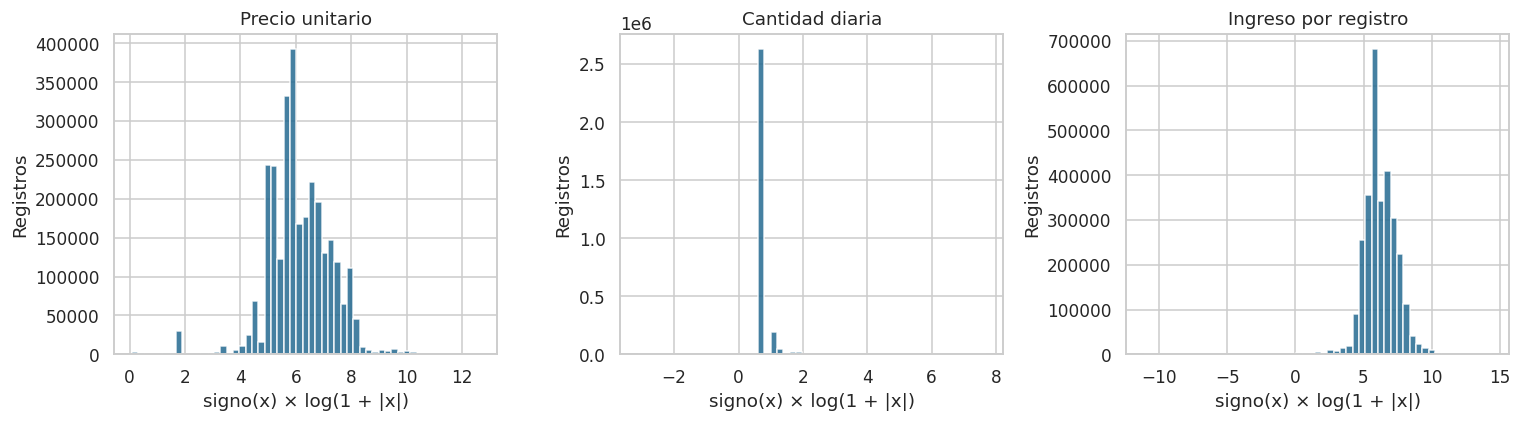

La escala logarítmica con signo permite visualizar colas y devoluciones sin borrarlas. Es una transformación de visualización; las estadísticas y agregaciones conservan la escala original.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes, ["item_price", "item_cnt_day", "ingresos"], ["Precio unitario", "Cantidad diaria", "Ingreso por registro"]):
    values = sales[col].dropna()
    if col == "item_price": values = values[values > 0]
    transformed = np.sign(values) * np.log1p(np.abs(values))
    ax.hist(transformed, bins=55, color="#246a91", alpha=.85)
    ax.set(title=title, xlabel="signo(x) × log(1 + |x|)", ylabel="Registros")
figure("01_distribuciones")
note("La escala logarítmica con signo permite visualizar colas y devoluciones sin borrarlas. "
     "Es una transformación de visualización; las estadísticas y agregaciones conservan la escala original.")

## 6. Exploración temporal

Se estudian tendencia, ciclos y cambios en el número de tiendas y productos con
actividad. Se usan promedios por día para comparar días de semana y meses con
distinta exposición. Estos patrones son descriptivos: no prueban por sí solos
estacionalidad estable ni explican las causas de los cambios.

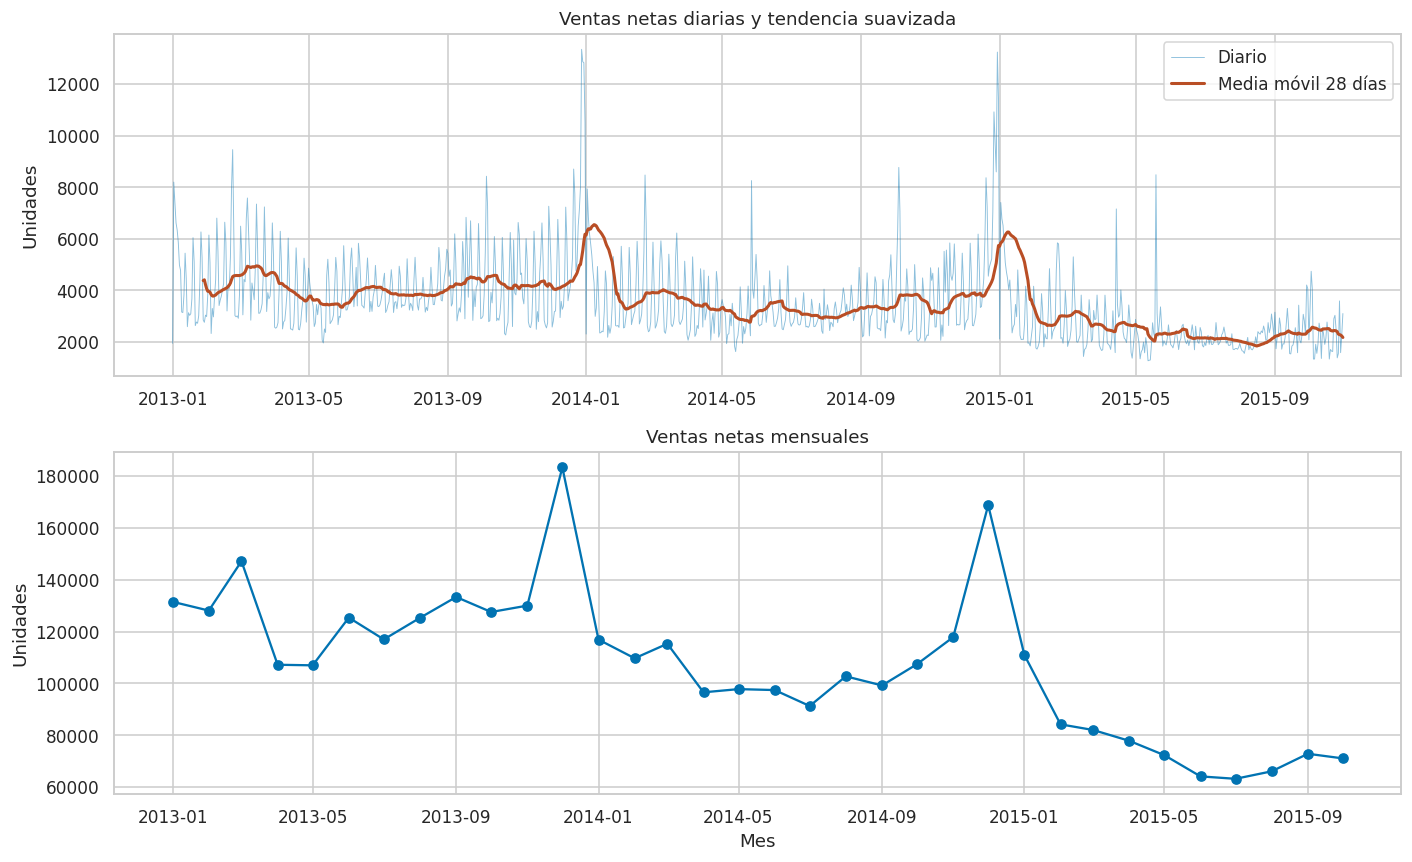

,variacion_porcentual
2014-01,-36.240
2015-01,-34.241
2013-04,-27.152
2013-06,17.211
2013-12,41.023
2014-12,43.200


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
anio,,,,
2013,"1,249,381.000","1,251,956.000","2,575.000","871,287,415.220"
2014,"1,034,285.000","1,036,485.000","2,200.000","962,711,712.660"
2015,"764,584.000","766,256.000","1,672.000","834,623,131.780"


El máximo mensual se observa en **2013-12**, con **183,342 unidades netas**; el mínimo en **2015-07**, con **63,187**. La tabla enero-octubre compara ventanas equivalentes entre años.

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].plot(daily.index, daily.item_cnt_day, lw=.6, alpha=.45, label="Diario")
axes[0].plot(daily.index, daily.item_cnt_day.rolling(28, min_periods=28).mean(), color="#b94e25", lw=2, label="Media móvil 28 días")
axes[0].set(title="Ventas netas diarias y tendencia suavizada", ylabel="Unidades")
axes[0].legend()
axes[1].plot(monthly.index.to_timestamp(), monthly.item_cnt_day, marker="o", label="Unidades mensuales")
axes[1].set(title="Ventas netas mensuales", ylabel="Unidades", xlabel="Mes")
figure("02_series_temporales")
changes = monthly.item_cnt_day.pct_change().mul(100).rename("variacion_porcentual").to_frame()
table(changes.sort_values("variacion_porcentual").dropna().iloc[np.r_[0:3, -3:0]], "cambios_mensuales_extremos")
comparable = sales.loc[sales.mes_calendario.le(10)].groupby("anio").agg(AGG)
table(comparable, "comparacion_enero_octubre")
note(f"El máximo mensual se observa en **{monthly.item_cnt_day.idxmax()}**, con "
     f"**{monthly.item_cnt_day.max():,.0f} unidades netas**; el mínimo en **{monthly.item_cnt_day.idxmin()}**, "
     f"con **{monthly.item_cnt_day.min():,.0f}**. La tabla enero-octubre compara ventanas equivalentes entre años.")

,mean,median,count
dia_semana,,,
0,"2,731.204","2,581.000",147
1,"3,074.223","2,659.000",148
2,"2,971.034","2,769.500",148
3,"3,071.770","2,925.500",148
4,"3,739.561","3,605.000",148
5,"4,963.824","4,911.000",148
6,"4,144.844","4,115.000",147


,mean,median,count
mes_calendario,,,
1,"3,863.957","3,401.000",93
2,"3,833.024","3,358.000",84
3,"3,703.785","3,263.000",93
4,"3,128.589","2,775.000",90
5,"2,979.075","2,738.000",93
6,"3,188.044","3,115.000",90
7,"2,918.624","2,795.000",93
8,"3,162.269","3,208.000",93
9,"3,393.144","3,092.500",90


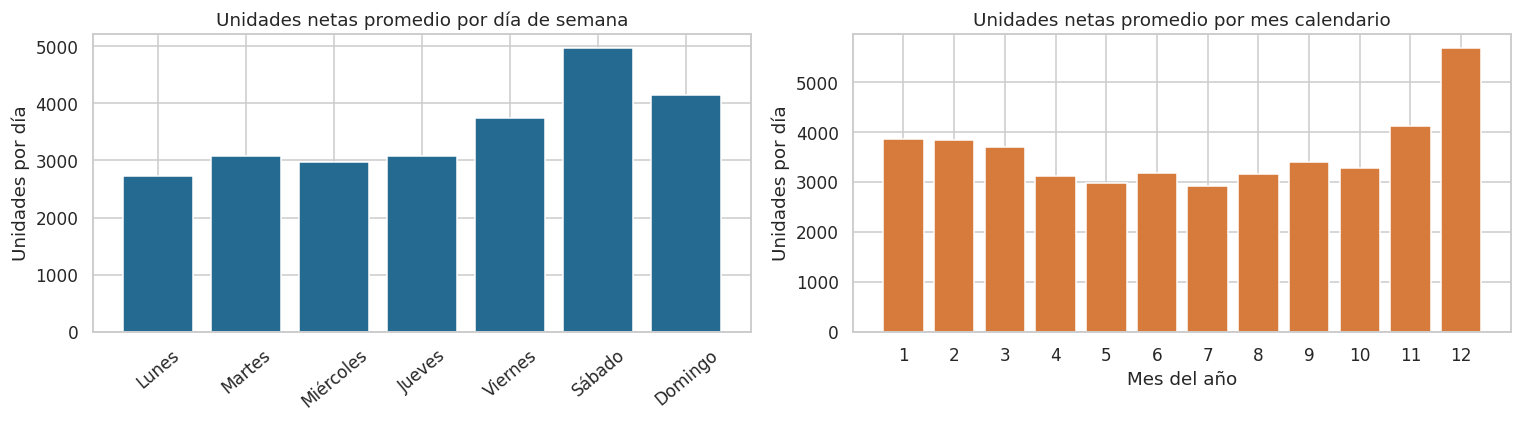

El promedio diario más alto corresponde a **Sábado**. Las diferencias mensuales mezclan tendencia y años distintos: noviembre y diciembre tienen menos años observados que enero-octubre.

In [10]:
weekday_names = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
weekday = daily.assign(dia_semana=daily.index.dayofweek).groupby("dia_semana").item_cnt_day.agg(["mean", "median", "count"])
calendar_month = daily.assign(mes_calendario=daily.index.month).groupby("mes_calendario").item_cnt_day.agg(["mean", "median", "count"])
table(weekday, "ciclos_dia_semana")
table(calendar_month, "ciclos_mes_calendario")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(weekday_names, weekday["mean"], color="#246a91")
axes[0].tick_params(axis="x", rotation=40)
axes[0].set(title="Unidades netas promedio por día de semana", ylabel="Unidades por día")
axes[1].bar(calendar_month.index, calendar_month["mean"], color="#d67b3c")
axes[1].set(title="Unidades netas promedio por mes calendario", xlabel="Mes del año", ylabel="Unidades por día")
axes[1].set_xticks(range(1, 13))
figure("03_ciclos_calendario")
note(f"El promedio diario más alto corresponde a **{weekday_names[int(weekday['mean'].idxmax())]}**. "
     "Las diferencias mensuales mezclan tendencia y años distintos: noviembre y diciembre tienen menos años observados que enero-octubre.")

,tiendas_activas,productos_activos,registros
mes,,,
2013-01,45,8115,115689
2013-02,46,8168,108613
2013-03,46,8302,121347
2013-04,46,8145,94109
2013-05,45,8339,91759
...,...,...,...
2015-06,43,5216,54617
2015-07,43,5323,55549
2015-08,42,5108,57029


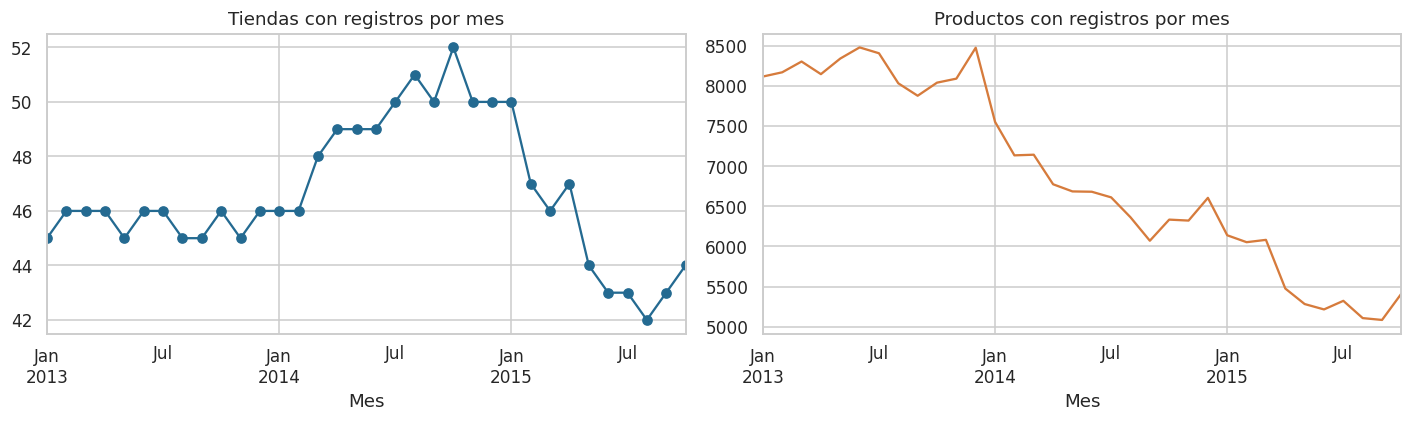

Los cambios de cobertura comercial pueden contribuir a los cambios del total agregado. No hay inventarios ni fechas de apertura/cierre para distinguir falta de demanda de falta de disponibilidad.

In [11]:
activity = sales.groupby("mes").agg(tiendas_activas=("shop_id", "nunique"), productos_activos=("item_id", "nunique"), registros=("item_id", "size"))
table(activity, "actividad_mensual", 34)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
activity.tiendas_activas.plot(ax=axes[0], marker="o", color="#246a91", title="Tiendas con registros por mes")
activity.productos_activos.plot(ax=axes[1], color="#d67b3c", title="Productos con registros por mes")
for ax in axes: ax.set_xlabel("Mes")
figure("04_actividad_mensual")
note("Los cambios de cobertura comercial pueden contribuir a los cambios del total agregado. "
     "No hay inventarios ni fechas de apertura/cierre para distinguir falta de demanda de falta de disponibilidad.")

## 7. Comparación entre sucursales, productos y anomalías

Los extremos se identifican, no se eliminan de forma automática. Un precio alto
puede corresponder a un producto distinto y una cantidad alta a una operación de
volumen. Se presenta sensibilidad al recorte como contraste, sin aplicarlo al EDA principal.

In [12]:
table(by_item.head(10).join(items.set_index("item_id")[["item_name"]]), "productos_mas_vendidos", 10)
table(by_item.tail(10).sort_values("item_cnt_day").join(items.set_index("item_id")[["item_name"]]), "productos_menos_vendidos", 10)
table(by_category.tail(10).sort_values("item_cnt_day"), "categorias_menos_vendidas", 10)
table(by_shop.tail(10).sort_values("item_cnt_day"), "tiendas_menor_venta", 10)
unsold_items = items.loc[~items.item_id.isin(sales.item_id)]
table(unsold_items, "catalogo_sin_ventas_observadas", 8)
table(sales.nlargest(10, "item_cnt_day")[list(raw.columns) + ["item_category_id", "shop_name"]], "cantidades_extremas", 10)
table(sales.nlargest(10, "item_price")[list(raw.columns) + ["item_category_id", "shop_name"]], "precios_extremos", 10)
q_price, q_units = sales.item_price.quantile(.999), sales.item_cnt_day.quantile(.999)
sales["extremo"] = sales.item_price.gt(q_price) | sales.item_cnt_day.abs().gt(q_units)
anomalies = sales.groupby("shop_id").agg(registros=("item_id", "size"), extremos=("extremo", "sum"))
anomalies["porcentaje_extremos"] = anomalies.extremos / anomalies.registros * 100
table(anomalies.sort_values("extremos", ascending=False), "extremos_por_tienda", 10)
sensitivity = pd.DataFrame({"original": monthly.item_cnt_day,
    "recorte_superior_p999": sales.assign(cantidad_recortada=sales.item_cnt_day.clip(upper=q_units)).groupby("mes").cantidad_recortada.sum()})
table(sensitivity, "sensibilidad_cantidades_extremas", 34)
note(f"Los umbrales exploratorios p99,9 son **{q_price:,.2f}** para precio y **{q_units:,.2f}** para cantidad. "
     "No son reglas de fraude ni justifican borrar observaciones. Los productos de menor venta incluyen devoluciones netas; "
     "los productos del catálogo sin historial se muestran aparte de los productos con ventas observadas.")

,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos,item_name
item_id,,,,,
20949,"187,642.000","187,660.000",18.000,"928,863.700",Фирменный пакет майка 1С Интерес белый (34*42)...
2808,"17,245.000","17,255.000",10.000,"16,852,778.420","Diablo III [PC, Jewel, русская версия]"
3732,"16,642.000","16,676.000",34.000,"43,617,975.480","Grand Theft Auto V [PS3, русские субтитры]"
17717,"15,830.000","15,830.000",0.000,"17,200,825.930",Прием денежных средств для 1С-Онлайн
5822,"14,515.000","14,522.000",7.000,"15,408,983.120",Playstation Store пополнение бумажника: Карта ...
3734,"11,688.000","11,733.000",45.000,"31,065,160.270","Grand Theft Auto V [Xbox 360, русские субтитры]"
6675,"10,289.000","10,315.000",26.000,"219,391,488.920",Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...
3731,"10,099.000","10,105.000",6.000,"19,983,482.890","Grand Theft Auto V [PC, русские субтитры]"
1855,"10,032.000","10,041.000",9.000,"9,357,024.780","Battlefield 4 [PC, русская версия]"


,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos,item_name
item_id,,,,,
1590,-11.000,3.000,14.000,"-28,589.000","Assassin’s Creed 3. Freedom Edition [PC, русск..."
13474,-1.000,0.000,1.000,"-10,398.000",Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...
18062,-1.000,0.000,1.000,"-4,999.000",Робопет Собака
11871,-1.000,0.000,1.000,"-5,999.000",Змея
8515,0.000,1.000,1.000,14.900,Английский язык. 2 - 5 класс (Jewel)
4591,0.000,1.000,1.000,0.000,"MCCARTNEY, PAUL In Red Square (Фирм.)"
13477,0.000,1.000,1.000,"-7,592.000",Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...
7547,0.000,1.000,1.000,0.000,VideoStudio Pro X6 IE Windows Mini-Box
10685,1.000,1.000,0.000,400.000,Головоломка Флаг*/Leonardo Flag* ар. 362014


,,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
item_category_id,item_category_name,,,,
10,Игровые консоли - PS2,1.000,1.000,0.000,"1,998.000"
51,Книги - Познавательная литература,1.000,1.000,0.000,129.000
1,Аксессуары - PS2,2.000,2.000,0.000,431.000
53,Книги - Художественная литература,3.000,3.000,0.000,847.000
52,Книги - Путеводители,3.000,3.000,0.000,300.000
50,Книги - Открытки,3.000,3.000,0.000,58.000
0,PC - Гарнитуры/Наушники,3.000,3.000,0.000,263.400
48,Книги - Компьютерная литература,6.000,6.000,0.000,"1,654.000"
27,Игры MAC - Цифра,8.000,8.000,0.000,"5,422.000"


,,item_cnt_day,unidades_positivas,unidades_devueltas,ingresos
shop_id,shop_name,,,,
36,"Новосибирск ТРЦ ""Галерея Новосибирск""",330.000,333.000,3.000,"377,714.000"
11,Жуковский ул. Чкалова 39м²,572.000,572.000,0.000,"521,655.140"
8,"Воронеж ТРЦ Сити-Парк ""Град""","3,595.000","3,602.000",7.000,"2,349,358.000"
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной","4,943.000","4,956.000",13.000,"4,293,586.850"
33,"Мытищи ТРК ""XL-3""","5,482.000","5,504.000",22.000,"5,949,101.570"
20,"Москва ""Распродажа""","5,872.000","5,873.000",1.000,"6,599,924.000"
1,"!Якутск ТЦ ""Центральный"" фран","6,311.000","6,311.000",0.000,"3,238,207.000"
34,"Н.Новгород ТРЦ ""РИО""","6,451.000","6,476.000",25.000,"8,582,822.010"
23,"Москва ТК ""Буденовский"" (пав.А2)","7,705.000","7,722.000",17.000,"5,621,521.200"


,item_name,item_id,item_category_id
83,12/ДВЕНАДЦАТЬ (СР) (Регион),83,40
140,1С:Аудиокниги. Аладдин и другие восточные сказ...,140,45
168,1С:Аудиокниги. Аудиокурсы по географии. 6 клас...,168,44
173,1С:Аудиокниги. Аудиоэнциклопедия для самых мал...,173,45
204,"1С:Аудиокниги. Г.Р. Хаггард. Клеопатра [PC, Ци...",204,44
237,"1С:Аудиокниги. Для самых маленьких. Сказки, по...",237,45
249,1С:Аудиокниги. Жюль Верн. Пятнадцатилетний кап...,249,45
254,1С:Аудиокниги. Илья Ильин. Если бы я был робин...,254,44


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_category_id,shop_name
2909812,2015-10-28,33,12,11373,0.909,"2,169.000",9,Интернет-магазин ЧС
2326924,2015-01-15,24,12,20949,4.000,"1,000.000",71,Интернет-магазин ЧС
2864229,2015-09-30,32,12,9248,"1,692.526",669.000,80,Интернет-магазин ЧС
2851085,2015-09-30,32,55,9249,"1,702.826",637.000,8,Цифровой склад 1С-Онлайн
2608034,2015-04-14,27,12,3731,"1,904.548",624.000,30,Интернет-магазин ЧС
2626175,2015-05-19,28,12,11373,155.193,539.000,9,Интернет-магазин ЧС
2851067,2015-09-29,32,55,9249,"1,500.000",533.000,8,Цифровой склад 1С-Онлайн
2048513,2014-10-02,21,12,9242,"1,500.000",512.000,8,Интернет-магазин ЧС
2067664,2014-10-09,21,55,19437,899.000,508.000,31,Цифровой склад 1С-Онлайн
2864254,2015-09-29,32,12,9248,"1,500.000",504.000,80,Интернет-магазин ЧС


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_category_id,shop_name
1163157,2013-12-13,11,12,6066,"307,980.000",1.000,75,Интернет-магазин ЧС
885137,2013-09-17,8,12,11365,"59,200.000",1.000,9,Интернет-магазин ЧС
1488133,2014-03-20,14,25,13199,"50,999.000",1.000,69,"Москва ТРК ""Атриум"""
2327153,2015-01-29,24,12,7241,"49,782.000",1.000,75,Интернет-магазин ЧС
2885686,2015-10-23,33,42,13403,"42,990.000",1.000,16,"СПб ТК ""Невский Центр"""
2910150,2015-10-29,33,12,13403,"42,990.000",1.000,16,Интернет-магазин ЧС
2917754,2015-10-20,33,3,13403,"42,990.000",1.000,16,"Балашиха ТРК ""Октябрь-Киномир"""
2931374,2015-10-20,33,22,13403,"42,990.000",1.000,16,Москва Магазин С21
1006637,2013-10-24,9,12,7238,"42,000.000",1.000,75,Интернет-магазин ЧС
2893094,2015-10-20,33,38,13403,"41,990.000",1.000,16,"Омск ТЦ ""Мега"""


,registros,extremos,porcentaje_extremos
shop_id,,,
31,235636,643,0.273
25,186103,478,0.257
12,34694,423,1.219
28,142234,328,0.231
54,143479,313,0.218
42,109252,296,0.271
27,105366,226,0.214
55,34769,170,0.489
6,82663,160,0.194


,original,recorte_superior_p999
2013-01,"131,478.000","131,395.000"
2013-02,"128,090.000","127,955.000"
2013-03,"147,142.000","146,566.000"
2013-04,"107,190.000","107,090.000"
2013-05,"106,970.000","106,371.000"
...,...,...
2015-06,"64,114.000","63,786.000"
2015-07,"63,187.000","63,006.000"
2015-08,"66,079.000","65,835.000"
2015-09,"72,843.000","67,204.000"


Los umbrales exploratorios p99,9 son **23,990.00** para precio y **22.00** para cantidad. No son reglas de fraude ni justifican borrar observaciones. Los productos de menor venta incluyen devoluciones netas; los productos del catálogo sin historial se muestran aparte de los productos con ventas observadas.

## 8. Visualizaciones obligatorias
La serie de ventas totales se presentó en el apartado 6. Aquí se añaden todas las
sucursales, productos top 10, categorías y matrices de comportamiento temporal.
Se usan IDs en los ejes para que los nombres largos no impidan leer las gráficas;
las tablas conservan los nombres originales.

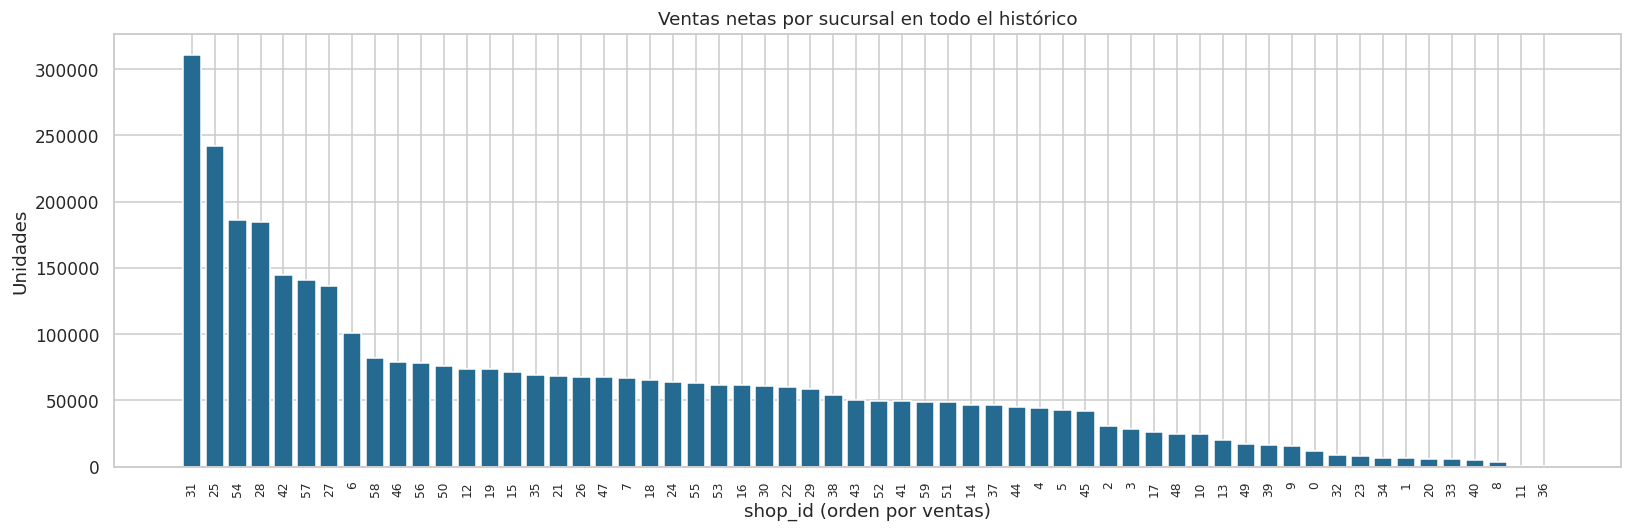

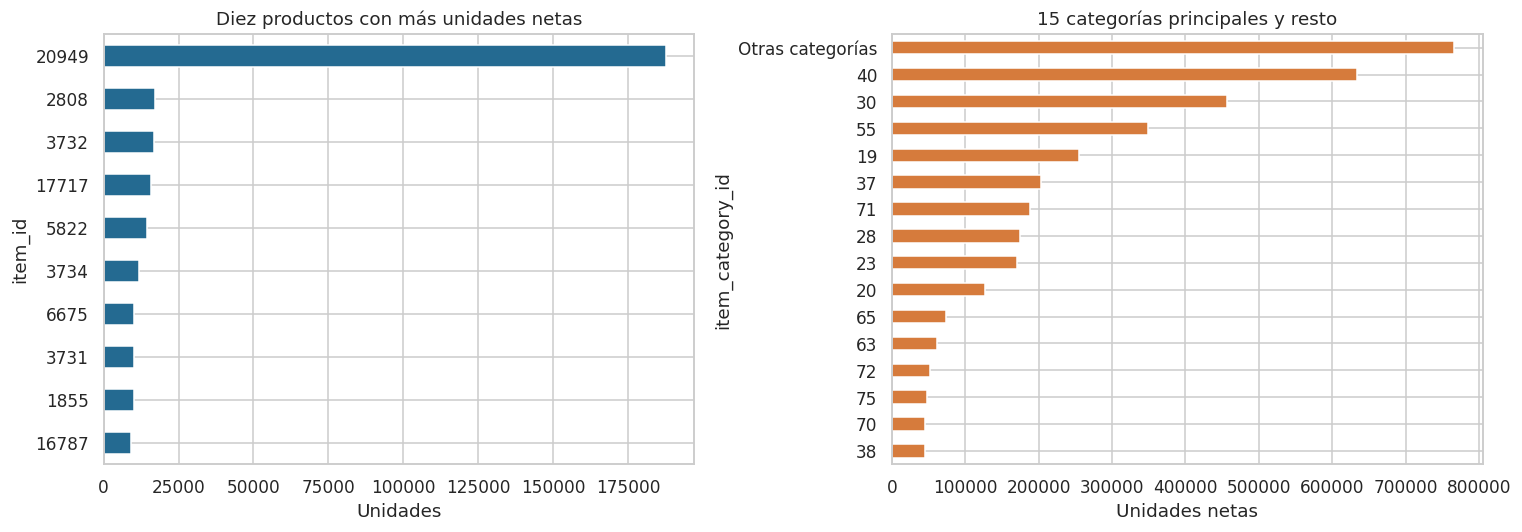

In [13]:
fig, ax = plt.subplots(figsize=(15, 5))
shop_order = by_shop.reset_index()
ax.bar(shop_order.shop_id.astype(str), shop_order.item_cnt_day, color="#246a91")
ax.set(title="Ventas netas por sucursal en todo el histórico", xlabel="shop_id (orden por ventas)", ylabel="Unidades")
ax.tick_params(axis="x", labelsize=8, rotation=90)
figure("05_ventas_todas_sucursales")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
by_item.head(10).item_cnt_day.sort_values().plot.barh(ax=axes[0], color="#246a91")
axes[0].set(title="Diez productos con más unidades netas", xlabel="Unidades", ylabel="item_id")
cat_order = by_category.reset_index()
cat_plot = cat_order.head(15).set_index("item_category_id").item_cnt_day
cat_plot.index = cat_plot.index.astype(str)
cat_plot.loc["Otras categorías"] = cat_order.iloc[15:].item_cnt_day.sum()
cat_plot.sort_values().plot.barh(ax=axes[1], color="#d67b3c")
axes[1].set(title="15 categorías principales y resto", xlabel="Unidades netas", ylabel="item_category_id")
figure("06_productos_y_categorias")

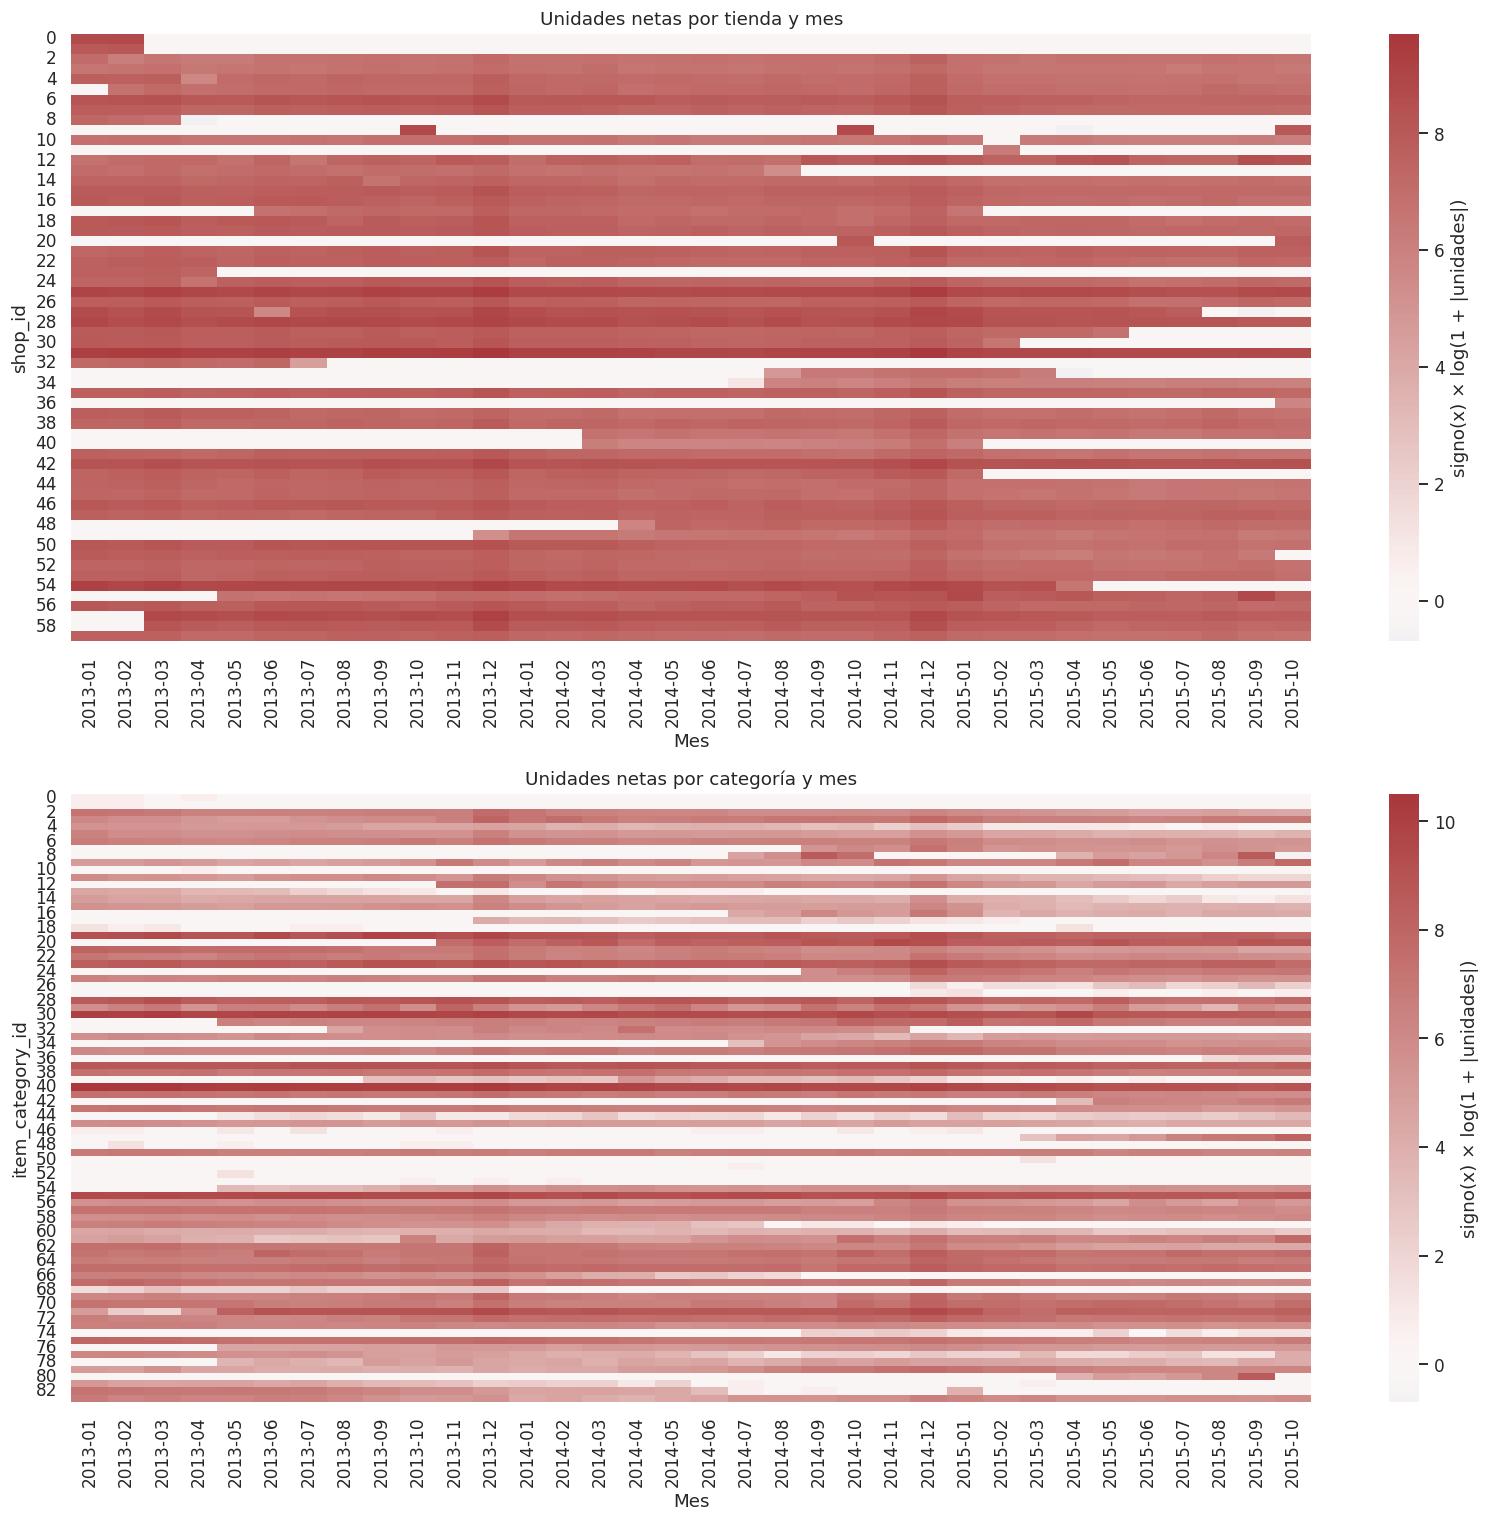

En estas matrices, cero significa ausencia de unidades netas registradas en la combinación, sin acreditar que hubiera stock o que la tienda estuviera abierta. La escala de color es logarítmica con signo.

In [14]:
shop_matrix = sales.pivot_table(index="shop_id", columns="mes", values="item_cnt_day", aggfunc="sum", fill_value=0).reindex(columns=MONTHS, fill_value=0)
category_matrix = sales.pivot_table(index="item_category_id", columns="mes", values="item_cnt_day", aggfunc="sum", fill_value=0).reindex(columns=MONTHS, fill_value=0)
fig, axes = plt.subplots(2, 1, figsize=(15, 14))
for ax, matrix, title in [(axes[0], shop_matrix, "Unidades netas por tienda y mes"), (axes[1], category_matrix, "Unidades netas por categoría y mes")]:
    shown = np.sign(matrix) * np.log1p(np.abs(matrix))
    sns.heatmap(shown, ax=ax, cmap="vlag", center=0, xticklabels=matrix.columns.astype(str), yticklabels=2,
                cbar_kws={"label": "signo(x) × log(1 + |unidades|)"})
    ax.set(title=title, xlabel="Mes")
figure("07_matrices_temporales")
note("En estas matrices, cero significa ausencia de unidades netas registradas en la combinación, "
     "sin acreditar que hubiera stock o que la tienda estuviera abierta. La escala de color es logarítmica con signo.")

## 9. Autocorrelación y autocorrelación parcial

Se analizan el total mensual y diario, y dos tiendas, productos y pares de alta
venta. La selección es ilustrativa y favorece series de mayor volumen; no representa
al azar todo el catálogo. Las series mensuales se alinean a los 34 meses, usando
cero cuando no se registra cantidad en ese mes. Esto no resuelve la disponibilidad
comercial desconocida. Las bandas del 95% son aproximadas, no se corrigen por
comparar múltiples rezagos y se interpretan con prudencia.

,nivel,shop_id,item_id,meses_con_registro
0,tienda,31.000,NaN,34
1,tienda,25.000,NaN,34
2,producto,NaN,"20,949.000",31
3,producto,NaN,"2,808.000",34
4,par,31.000,"20,949.000",30
5,par,25.000,"20,949.000",29


**Total mensual**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1, 2. Rezagos PACF: 1. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

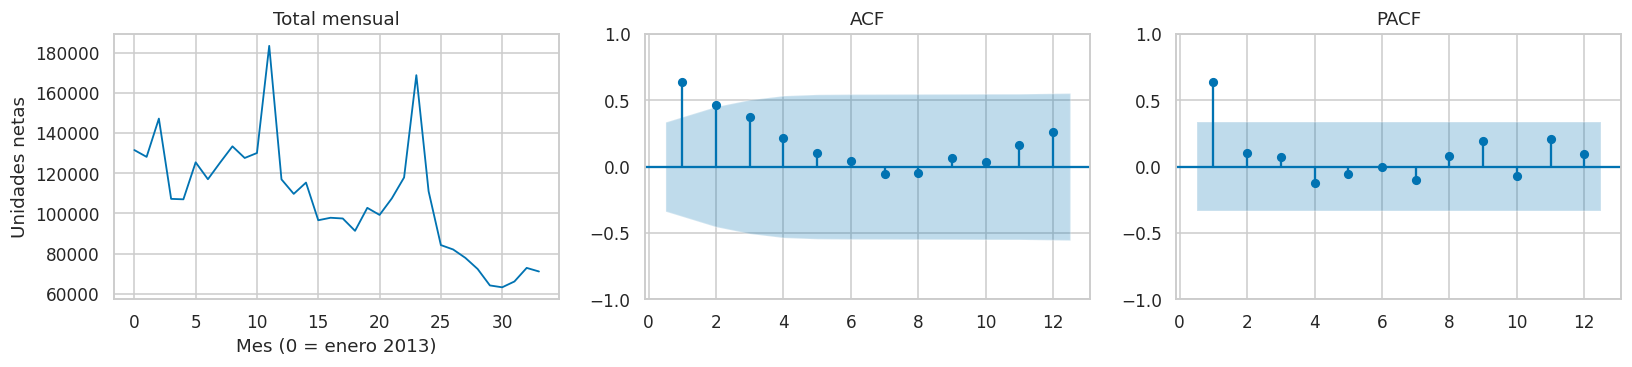

**Total diario**: 1034 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 21, 22, 27, 28, 29, 34, 35. Rezagos PACF: 1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21, 22, 27, 28, 29, 34, 35. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

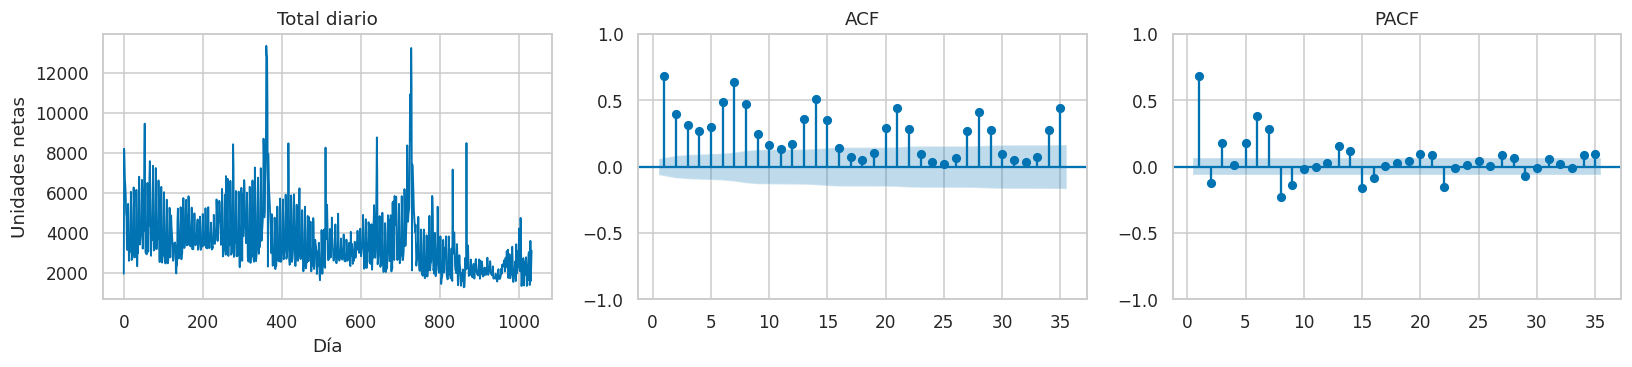

**Tienda 31**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1. Rezagos PACF: 1. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

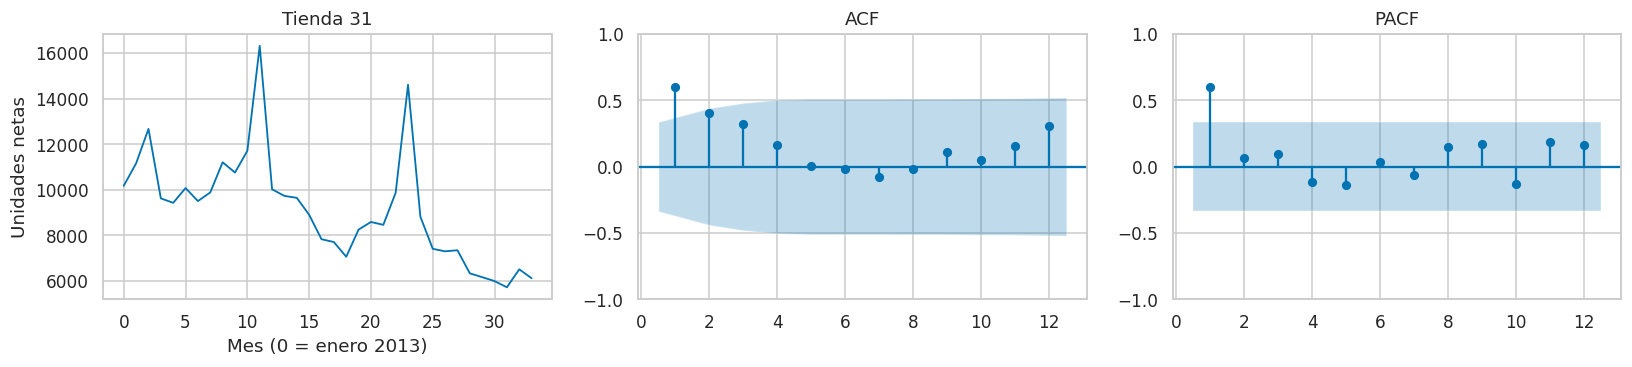

**Tienda 25**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1. Rezagos PACF: 1. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

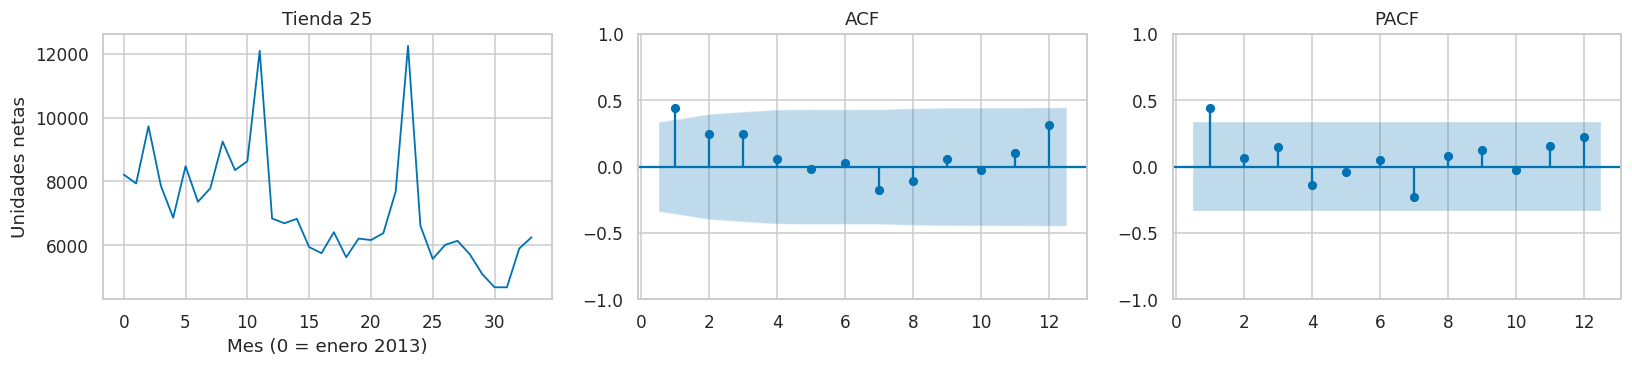

**Producto 20949**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1. Rezagos PACF: 1, 7. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

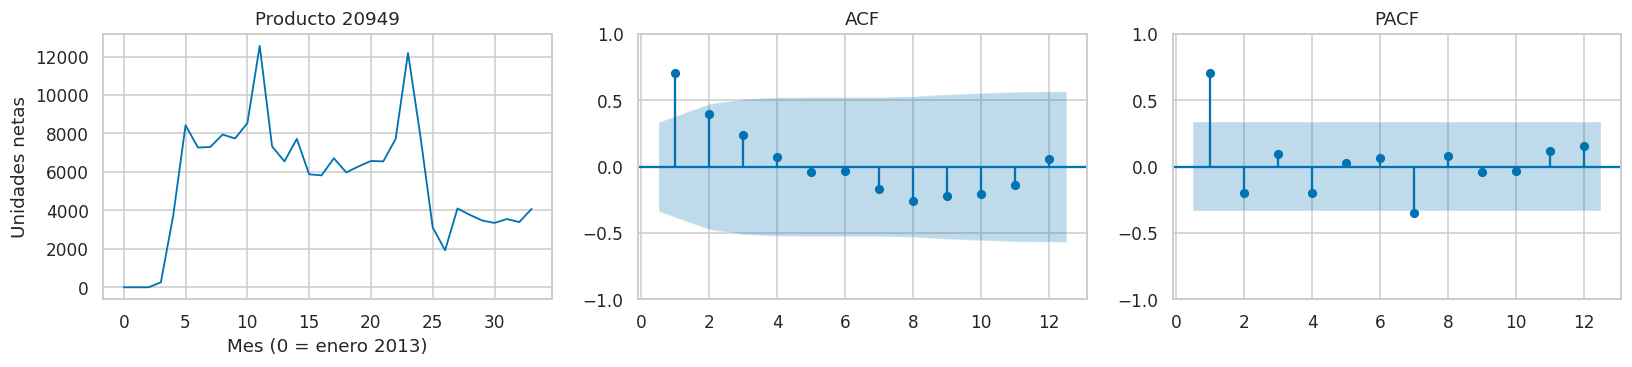

**Producto 2808**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1. Rezagos PACF: 1. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

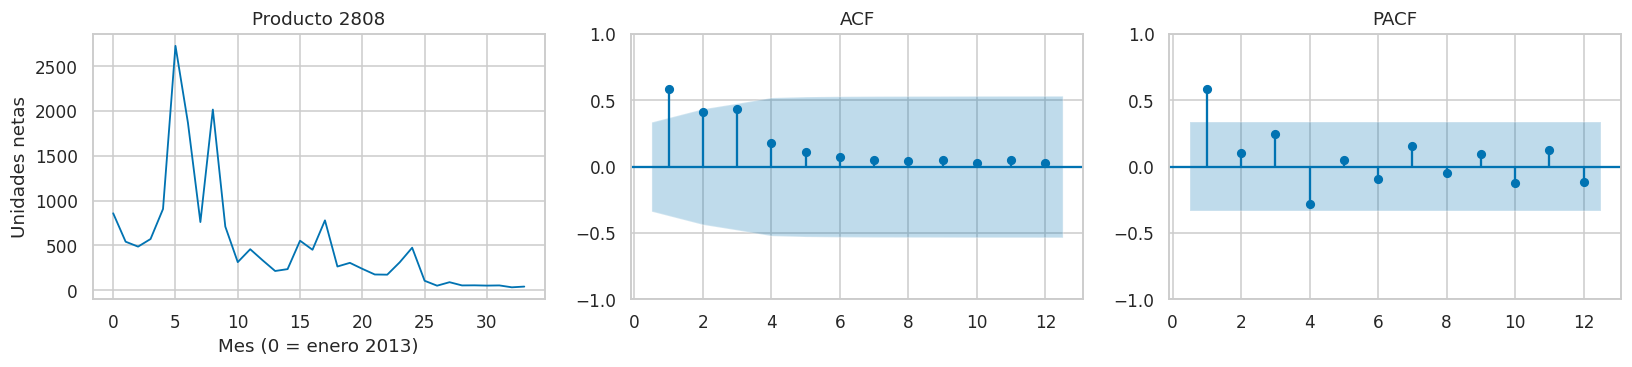

**Tienda 31 / producto 20949**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1. Rezagos PACF: 1. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

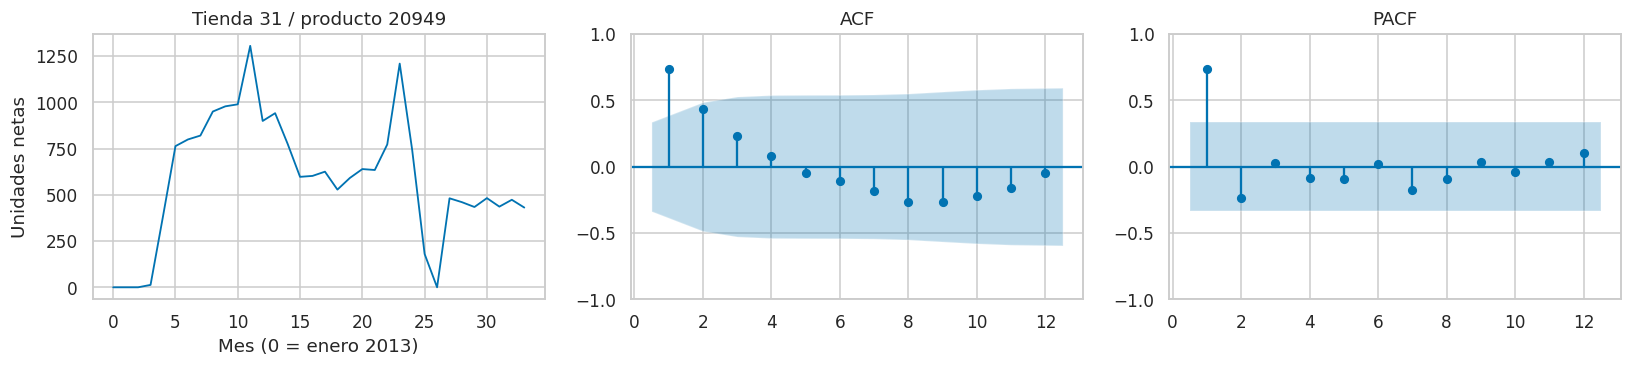

**Tienda 25 / producto 20949**: 34 observaciones. Rezagos ACF fuera de las bandas aproximadas: 1. Rezagos PACF: 1, 7. ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.

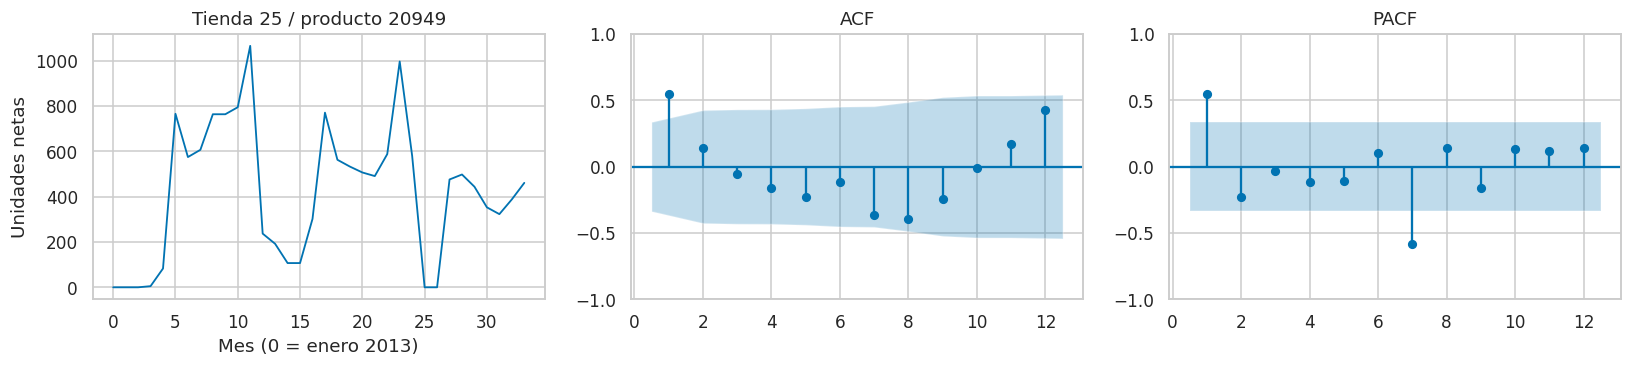

,serie,n,rezago,acf,pacf,acf_significativa,pacf_significativa
0,Total mensual,34,1,0.638,0.638,True,True
1,Total mensual,34,2,0.466,0.099,True,False
2,Total mensual,34,3,0.374,0.073,False,False
3,Total mensual,34,4,0.211,-0.126,False,False
4,Total mensual,34,5,0.099,-0.059,False,False
5,Total mensual,34,6,0.044,-0.003,False,False
6,Total mensual,34,7,-0.056,-0.099,False,False
7,Total mensual,34,8,-0.046,0.076,False,False
8,Total mensual,34,9,0.067,0.196,False,False
9,Total mensual,34,10,0.035,-0.070,False,False


In [15]:
selected_shops = by_shop.head(2).reset_index().shop_id.tolist()
selected_items = by_item.head(2).index.tolist()
by_pair = sales.groupby(["shop_id", "item_id"]).item_cnt_day.sum().sort_values(ascending=False)
selected_pairs = by_pair.head(2).index.tolist()
series = {"Total mensual": monthly.item_cnt_day, "Total diario": daily.item_cnt_day}
selection = []
for shop in selected_shops:
    values = shop_matrix.loc[shop]
    series[f"Tienda {shop}"] = values
    selection.append({"nivel": "tienda", "shop_id": shop, "item_id": None, "meses_con_registro": int((sales.loc[sales.shop_id.eq(shop)].mes.nunique()))})
for item in selected_items:
    part = sales.loc[sales.item_id.eq(item)]
    series[f"Producto {item}"] = part.groupby("mes").item_cnt_day.sum().reindex(MONTHS, fill_value=0)
    selection.append({"nivel": "producto", "shop_id": None, "item_id": item, "meses_con_registro": int(part.mes.nunique())})
for shop, item in selected_pairs:
    part = sales.loc[sales.shop_id.eq(shop) & sales.item_id.eq(item)]
    series[f"Tienda {shop} / producto {item}"] = part.groupby("mes").item_cnt_day.sum().reindex(MONTHS, fill_value=0)
    selection.append({"nivel": "par", "shop_id": shop, "item_id": item, "meses_con_registro": int(part.mes.nunique())})
table(pd.DataFrame(selection), "series_seleccionadas", 10)
correlations = []
for pos, (label, values) in enumerate(series.items()):
    n = len(values)
    lags = min(35 if label == "Total diario" else 12, n // 2 - 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    axes[0].plot(np.arange(n), values.to_numpy(), lw=1.2)
    axes[0].set(title=label, xlabel="Día" if label == "Total diario" else "Mes (0 = enero 2013)", ylabel="Unidades netas")
    if values.nunique() > 1:
        plot_acf(values, lags=lags, zero=False, alpha=.05, ax=axes[1], title="ACF")
        plot_pacf(values, lags=lags, zero=False, alpha=.05, method="ywm", ax=axes[2], title="PACF")
        a, a_ci = acf(values, nlags=lags, alpha=.05, fft=True)
        p, p_ci = pacf(values, nlags=lags, alpha=.05, method="ywm")
        for lag in range(1, lags + 1):
            correlations.append({"serie": label, "n": n, "rezago": lag, "acf": a[lag], "pacf": p[lag],
                "acf_significativa": bool(a_ci[lag, 0] > 0 or a_ci[lag, 1] < 0),
                "pacf_significativa": bool(p_ci[lag, 0] > 0 or p_ci[lag, 1] < 0)})
        sig = [str(k) for k in range(1, lags + 1) if a_ci[k, 0] > 0 or a_ci[k, 1] < 0]
        sig_p = [str(k) for k in range(1, lags + 1) if p_ci[k, 0] > 0 or p_ci[k, 1] < 0]
        note(f"**{label}**: {n} observaciones. Rezagos ACF fuera de las bandas aproximadas: "
             + (", ".join(sig) if sig else "ninguno") + ". Rezagos PACF: "
             + (", ".join(sig_p) if sig_p else "ninguno")
             + ". ACF describe persistencia total; PACF contrasta la asociación restante al controlar rezagos intermedios.")
    else:
        note(f"**{label}** es constante; no se calcula autocorrelación.")
    figure(f"08_acf_pacf_{pos:02}")
correlations = pd.DataFrame(correlations)
table(correlations, "autocorrelaciones", 15)

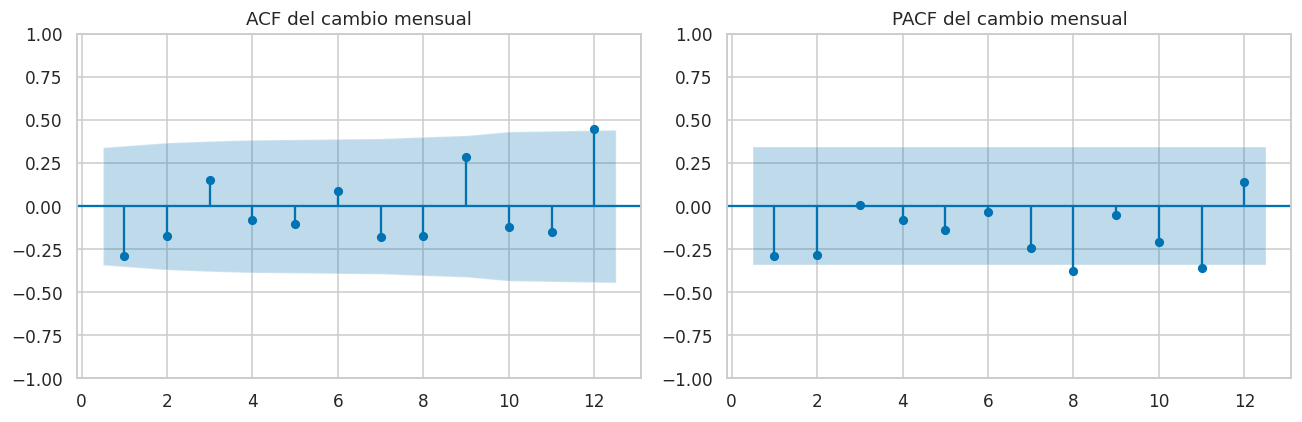

,serie,n,rezago,acf,pacf,acf_significativa,pacf_significativa
0,Total mensual,34,1,0.638,0.638,True,True
11,Total mensual,34,12,0.259,0.094,False,False
18,Total diario,1034,7,0.636,0.282,True,True
25,Total diario,1034,14,0.506,0.115,True,True
32,Total diario,1034,21,0.440,0.085,True,True
39,Total diario,1034,28,0.413,0.061,True,True


El total diario presenta ACF a 7 días de **0.636**, fuera de las bandas aproximadas; los rezagos semanales repetidos y la gráfica por día de semana son compatibles con un ciclo semanal. En el total mensual, la ACF a 12 meses es **0.259**, dentro de las bandas. Esta muestra corta no permite afirmar una estacionalidad anual estable ni descartar que exista.

Se contrasta el nivel con el cambio mensual para reconocer que la tendencia puede producir dependencia persistente. Los rezagos 7, 14 y 28 días orientan la revisión de un posible ciclo semanal. El rezago 12 meses tiene muy pocos ciclos anuales disponibles. Una ACF significativa aislada no prueba estacionalidad y la PACF no determina por sí sola el orden final de un modelo: harán falta validación temporal y diagnóstico de residuos.

In [16]:
delta = monthly.item_cnt_day.diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(delta, lags=12, zero=False, ax=axes[0], title="ACF del cambio mensual")
plot_pacf(delta, lags=12, zero=False, method="ywm", ax=axes[1], title="PACF del cambio mensual")
figure("09_autocorrelacion_cambio_mensual")
selected_lags = correlations.loc[((correlations.serie.eq("Total diario")) & correlations.rezago.isin([7, 14, 21, 28])) |
                                ((correlations.serie.eq("Total mensual")) & correlations.rezago.isin([1, 12]))]
table(selected_lags, "rezagos_calendario")
a7 = selected_lags.loc[selected_lags.serie.eq("Total diario") & selected_lags.rezago.eq(7)].iloc[0]
a12 = selected_lags.loc[selected_lags.serie.eq("Total mensual") & selected_lags.rezago.eq(12)].iloc[0]
note(f"El total diario presenta ACF a 7 días de **{a7.acf:.3f}**, "
     + ("fuera" if a7.acf_significativa else "dentro") + " de las bandas aproximadas; los rezagos semanales repetidos "
     "y la gráfica por día de semana son compatibles con un ciclo semanal. "
     f"En el total mensual, la ACF a 12 meses es **{a12.acf:.3f}**, "
     + ("fuera" if a12.acf_significativa else "dentro") + " de las bandas. "
     "Esta muestra corta no permite afirmar una estacionalidad anual estable ni descartar que exista.")
note("Se contrasta el nivel con el cambio mensual para reconocer que la tendencia puede producir dependencia persistente. "
     "Los rezagos 7, 14 y 28 días orientan la revisión de un posible ciclo semanal. El rezago 12 meses tiene "
     "muy pocos ciclos anuales disponibles. Una ACF significativa aislada no prueba estacionalidad y la PACF "
     "no determina por sí sola el orden final de un modelo: harán falta validación temporal y diagnóstico de residuos.")

## 10. Hallazgos y preparación para forecasting

La cobertura se calcula con los IDs originales y pares únicos. Un par con historial
puede llevar meses inactivo; por ello también se mide presencia en octubre de 2015.
No tener historial del par no equivale a que ni la tienda ni el producto sean nuevos.

In [17]:
history_pairs = pd.MultiIndex.from_frame(sales[["shop_id", "item_id"]].drop_duplicates())
test_pairs = pd.MultiIndex.from_frame(test[["shop_id", "item_id"]])
last_pairs = pd.MultiIndex.from_frame(sales.loc[sales.mes.eq(MONTHS[-1]), ["shop_id", "item_id"]].drop_duplicates())
coverage = test.copy()
coverage["par_con_historial"] = test_pairs.isin(history_pairs)
coverage["par_con_registro_octubre"] = test_pairs.isin(last_pairs)
coverage["producto_con_historial"] = test.item_id.isin(sales.item_id)
coverage["tienda_con_historial"] = test.shop_id.isin(sales.shop_id)
coverage_summary = coverage.iloc[:, 3:].agg(["sum", "mean"]).T.rename(columns={"sum": "pares", "mean": "proporcion"})
coverage_summary["porcentaje"] = coverage_summary.proporcion * 100
table(coverage_summary, "cobertura_test")
table(coverage.groupby(["tienda_con_historial", "producto_con_historial", "par_con_historial"]).size().rename("pares").to_frame(), "tipos_historial_test")
coverage.to_csv(ROOT / "data/processed/cobertura_por_par_test.csv", index=False)
coverage_pct = coverage.par_con_historial.mean() * 100
shop_share = by_shop.head(5).item_cnt_day.sum() / sales.item_cnt_day.sum() * 100
category_share = by_category.head(5).item_cnt_day.sum() / sales.item_cnt_day.sum() * 100
note(f"""### Conclusiones basadas en la ejecución

- **Cobertura del objetivo:** {coverage.par_con_historial.sum():,} de {len(test):,} pares de test tienen historial: **{coverage_pct:.2f}%**.
  El resto requiere resolver combinaciones sin historia; no basta con un modelo separado para cada par.
- **Recencia:** solo **{coverage.par_con_registro_octubre.mean()*100:.2f}%** de los pares tiene registros en octubre.
  Se debe distinguir historia remota, ausencia reciente y producto nuevo.
- **Concentración:** las cinco tiendas de mayor volumen reúnen **{shop_share:.2f}%** de las unidades netas y las cinco categorías principales **{category_share:.2f}%**.
  Conviene examinar errores por tienda y categoría, además del error total.
- **Variables candidatas:** calendario, identificación de tienda/producto/categoría, rezagos de cantidades y estadísticas móviles.
  Los precios contemporáneos de noviembre no se conocen en test; no deben introducirse como si estuvieran disponibles.
- **Calidad:** fechas y claves son consistentes y no hay nulos originales; se documentan los duplicados, devoluciones,
  el precio inválido, candidatos a alias y extremos. La falta de nulos no significa ausencia de problemas de negocio.
- **Temporalidad:** los patrones del total mezclan demanda y cambios de cobertura. Los ciclos sugeridos por ACF/PACF
  deben contrastarse fuera de muestra; 34 meses no bastan para afirmar un patrón anual estable para todas las series.
- **Siguiente etapa:** construir una tabla mensual tienda-producto; definir cómo representar meses sin registro y el universo de pares;
  crear rezagos mediante desplazamiento; separar entrenamiento y validación por fecha, por ejemplo entrenar hasta septiembre
  y validar octubre, seguido de varias ventanas retrospectivas. Ajustar transformaciones usando solo cada entrenamiento.

La exploración de todo el histórico es descriptiva. La selección de variables y transformaciones para un modelo se repetirá
dentro de sus ventanas de entrenamiento para evitar fuga de información. No se han atribuido causas a picos o caídas
que el conjunto no documenta.
""")

,pares,proporcion,porcentaje
par_con_historial,"111,404.000",0.520,52.009
par_con_registro_octubre,"28,680.000",0.134,13.389
producto_con_historial,"198,954.000",0.929,92.882
tienda_con_historial,"214,200.000",1.000,100.000


pares
tienda_con_historial producto_con_historial par_con_historial        
True                 False                  False               15246
                     True                   False               87550
                                            True               111404

### Conclusiones basadas en la ejecución

- **Cobertura del objetivo:** 111,404 de 214,200 pares de test tienen historial: **52.01%**.
  El resto requiere resolver combinaciones sin historia; no basta con un modelo separado para cada par.
- **Recencia:** solo **13.39%** de los pares tiene registros en octubre.
  Se debe distinguir historia remota, ausencia reciente y producto nuevo.
- **Concentración:** las cinco tiendas de mayor volumen reúnen **29.27%** de las unidades netas y las cinco categorías principales **52.01%**.
  Conviene examinar errores por tienda y categoría, además del error total.
- **Variables candidatas:** calendario, identificación de tienda/producto/categoría, rezagos de cantidades y estadísticas móviles.
  Los precios contemporáneos de noviembre no se conocen en test; no deben introducirse como si estuvieran disponibles.
- **Calidad:** fechas y claves son consistentes y no hay nulos originales; se documentan los duplicados, devoluciones,
  el precio inválido, candidatos a alias y extremos. La falta de nulos no significa ausencia de problemas de negocio.
- **Temporalidad:** los patrones del total mezclan demanda y cambios de cobertura. Los ciclos sugeridos por ACF/PACF
  deben contrastarse fuera de muestra; 34 meses no bastan para afirmar un patrón anual estable para todas las series.
- **Siguiente etapa:** construir una tabla mensual tienda-producto; definir cómo representar meses sin registro y el universo de pares;
  crear rezagos mediante desplazamiento; separar entrenamiento y validación por fecha, por ejemplo entrenar hasta septiembre
  y validar octubre, seguido de varias ventanas retrospectivas. Ajustar transformaciones usando solo cada entrenamiento.

La exploración de todo el histórico es descriptiva. La selección de variables y transformaciones para un modelo se repetirá
dentro de sus ventanas de entrenamiento para evitar fuga de información. No se han atribuido causas a picos o caídas
que el conjunto no documenta.


In [18]:
summary = {"filas_originales": len(raw), "filas_analisis": len(sales), "meses": len(MONTHS),
           "duplicados": duplicates_n, "precios_invalidos": int((~sales.precio_valido).sum()),
           "registros_devolucion": int(sales.item_cnt_day.lt(0).sum()),
           "unidades_netas": float(sales.item_cnt_day.sum()), "pares_test": len(test),
           "pares_test_con_historial": int(coverage.par_con_historial.sum()), "cobertura_test_pct": coverage_pct,
           "python": sys.version.split()[0], "raw_sha256": raw_hashes}
(ROOT / "reports/resumen_eda.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
assert all(hashlib.sha256((RAW / name).read_bytes()).hexdigest() == value for name, value in raw_hashes.items())
note("**Ejecución terminada.** Las tablas y gráficas se guardaron en `reports/`. Los CSV originales conservan sus hashes. "
     "Faltan las acciones externas del equipo: publicar en GitHub y adjuntar capturas reales del pull.")

**Ejecución terminada.** Las tablas y gráficas se guardaron en `reports/`. Los CSV originales conservan sus hashes. Faltan las acciones externas del equipo: publicar en GitHub y adjuntar capturas reales del pull.